# Lung: cell–matrix association and recovery of ECM labels from cell context (Figure 4)

This notebook reproduces Figure 4 of the paper, panels a to j, from the raw images. The data are six
imaging-mass-cytometry regions of interest (ROIs) of healthy mouse lung from two mice, with 12 annotated cell
types and ten extracellular-matrix (ECM) markers.

- **Data:** downloaded by `mt.datasets.balbc_pbs_lung()` from Zenodo
  ([10.5281/zenodo.21538382](https://doi.org/10.5281/zenodo.21538382)): the images, the marker panel and the
  segmented cells with their cell types.
- **Analysis:** ECM patches and their clusters, the cell–ECM graph, the ECM cluster and the markers that airway
  epithelial cells (AECs) contact, and the recovery of corrupted ECM labels from the cells around each patch.
- **Run time:** about 1 minute on a desktop CPU with the data already downloaded, or about 4 minutes on Google
  Colab's free CPU runtime. No GPU is needed.

Everything is computed here: the patches, the clusters, the graphs and the classifiers. The one input taken from
the paper's analysis is `lung_selected.json`, which holds the graph, feature and classifier settings that the
paper selected within each training mouse (Supplementary Table 6). The search that chose them is not rerun.
Each panel is followed by a comparison with the paper's values, joined on explicit keys (cluster, ROI, marker,
patch, context). The last section puts the paper's values and this run's in one table.

How the notebook is organised:

| Section | Content |
|---|---|
| 1 | Load the cells, the images and the paper's values |
| 2 | ECM patches and clusters (panel d) |
| 3 | The cell–ECM graph (panels a–c) |
| 4 | The ECM cluster that AECs contact (panel e) |
| 5 | The markers that AECs contact inside ECM 1 (panels f, g) |
| 6 | Recovery of corrupted ECM labels from context (panels h–j) |
| 7 | The paper's results beside the results of this notebook |

The Mantpy functions used:

| Step | Mantpy function |
|---|---|
| Load the dataset | `mt.datasets.balbc_pbs_lung` |
| Patch features from the images | `mt.pp.ecm_patches_from_images` |
| Number of clusters, clustering, background | `mt.pp.select_ecm_cluster_count`, `mt.pp.cluster_ecm_patches`, `mt.pp.remove_background_patches` |
| The paper's cluster numbers | `mt.pl.ecm_centroid_table`, `mt.pp.renumber_ecm_clusters` |
| Patches attached to the cells | `mt.pp.attach_ecm_patches` |
| Graphs | `mt.gr.build_cell_ecm_graphs`, `mt.gr.graph_layers` |
| Graph drawings | `mt.pl.cell_graph`, `mt.pl.ecm_graph`, `mt.pl.cell_ecm_graph` |
| Marker profiles of the clusters | `mt.pl.ecm_centroid_heatmap` |
| Cell–ECM association | `mt.tl.cell_ecm_enrichment`, `mt.pl.cell_ecm_enrichment_bars` |
| Markers of contacted patches | `mt.tl.cell_ecm_marker_contrast`, `mt.pl.marker_contrast_bars` |
| Label corruption | `mt.tl.corrupt_labels` |
| Context of each patch | `mt.tl.context_features` |
| Anomaly scores and relabelling | `mt.tl.fit_temperature`, `mt.tl.label_anomaly_scores`, `mt.tl.reconstruct_labels_iteratively` |
| Scores of the reconstruction | `mt.tl.score_label_reconstruction` |
| Label maps | `mt.pl.patch_map` |

Requires `mantpy` 1.3.0 or newer and the packages in `lung_requirements.txt`. Keep `lung_helpers.py` and
`lung_selected.json` beside this notebook. The helper file holds what is specific to reproducing the paper:
reading the paper's values, matching the clusters of this run to the paper's, the comparison tables, the
translation of the selected settings into Mantpy arguments, and the parts of the panels that Mantpy does not
draw. Each of its functions takes everything it uses as an argument.

In [1]:
# Google Colab only: fetch this repository and install the packages. Skipped on your own computer.
# After installing, the runtime restarts so that the installed versions are the ones in use. Colab reports
# this as a crashed session, which is expected: choose Runtime > Run all again.
import os, subprocess, sys, time

REVISION = "main"   # the repository revision this notebook was run from

if "google.colab" in sys.modules:
    repository = "/content/mantpy_reproducibility"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "https://github.com/moeghaf/mantpy_reproducibility", repository], check=True)
    subprocess.run(["git", "-C", repository, "checkout", "--quiet", REVISION], check=True)
    os.chdir(f"{repository}/notebooks")
    installed = "/content/lung_packages_installed"
    if not os.path.exists(installed):
        pip = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "lung_requirements.txt"],
                             capture_output=True, text=True)
        if pip.returncode != 0:
            raise RuntimeError(pip.stderr[-3000:])
        open(installed, "w").close()
        print("Packages installed. The runtime restarts now: choose Runtime > Run all again.", flush=True)
        time.sleep(2)   # gives the line above time to reach the page
        os.kill(os.getpid(), 9)

In [2]:
import json, time, warnings
from pathlib import Path

# Known messages that would repeat for every ROI are hidden here, each by its text.
# Every other warning is shown.
for message, category in (
    (r"'\w+' is not a valid key!", SyntaxWarning),                             # raised when Squidpy is imported
    (r"Calling `spatial_neighbors` is deprecated", FutureWarning),             # Squidpy 1.8, called inside Mantpy
    (r"Parameter `n_neighs` is ignored when `radius` is set", FutureWarning),  # the same call
    (r"IProgress not found", Warning),                                         # only concerns progress bars
):
    warnings.filterwarnings("ignore", message=message, category=category)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from threadpoolctl import threadpool_limits

import mantpy as mt
import lung_helpers as lh

if not hasattr(mt.tl, "cell_ecm_marker_contrast"):
    raise RuntimeError("This notebook needs Mantpy 1.3.0 or newer (pip install -U mantpy).")

STARTED = time.perf_counter()
print("Mantpy", mt.__version__)

Mantpy 1.3.0


The settings of the analysis and the paper's values. `lh.read_paper_values` reads the paper's source data
(`source_data/fig4.xlsx`) into one table per quantity, each with explicit keys.

In [3]:
SEED = 0
PATCH_SIZE = 10            # pixels (1 pixel = 1 µm)
GRAPH_ROI = "roi_001"      # ROI drawn in panels a-c and g
EXAMPLE_ROI = "roi_004"    # held-out ROI drawn in panels h and i (mouse 2)
CELL_TYPE = "AEC"          # airway epithelial cells
WALL = 1                   # ECM 1, the bronchovascular-wall cluster
N_REALISATIONS = 5         # corruptions of every ROI

CONTEXTS = ["cell", "joint", "ecm"]
CONTEXT_NAMES = {"cell": "Cell context", "joint": "Joint context", "ecm": "ECM context"}
MOUSE_MARK = {"mouse_01": "o", "mouse_02": "^"}

# The settings selected within each training mouse (Supplementary Table 6), keyed by the held-out mouse.
SETTINGS = json.loads(Path("lung_selected.json").read_text(encoding="utf8"))["mouse"]
PAPER = lh.read_paper_values("../source_data/fig4.xlsx")

## 1. Load the data

`mt.datasets.balbc_pbs_lung` downloads the dataset once and returns the cells of every ROI (one AnnData each,
with the cell type in `obs["cell_type"]`), the images, the marker panel and the names of the ten ECM markers.

In [4]:
bundle = mt.datasets.balbc_pbs_lung()
cells = bundle.cohort_cells                    # one AnnData of cells per ROI
ROIS = list(cells)
MARKERS = list(bundle.ecm_names)               # the ten ECM markers, in the order of the patch features
ECM = bundle.ecm_palette                       # the colour of each ECM cluster
mouse = bundle.metadata.set_index("sample_id")["Mouse"].astype(str)
CELL_TYPES = sorted(set().union(*[set(adata.obs["cell_type"].astype(str)) for adata in cells.values()]))

assert ROIS == list(bundle.images) == list(mouse.index), "cells, images and metadata must list the same ROIs"
assert len(MARKERS) == 10 and len(CELL_TYPES) == 12
assert mouse.value_counts().to_dict() == {"mouse_01": 3, "mouse_02": 3}
assert set(SETTINGS) == set(mouse) and all(set(SETTINGS[m]) == set(CONTEXTS) for m in SETTINGS)

print("ECM markers:", ", ".join(MARKERS))
print("Cell types: ", ", ".join(CELL_TYPES))
bundle.metadata[["sample_id", "Mouse", "strain", "treatment"]].assign(cells=[cells[roi].n_obs for roi in ROIS])

ECM markers: HABP, Col-VI, HepSul, Col-IV, Chon-Sul, Fibrinogen, Col-III, Fibronectin, lamg1, Col-I
Cell types:  AEC, ATI, ATII, Alveolar Fibroblast, Alveolar Macrophages, B Cells, CD11b Immune, Endothelial, Fibroblast, Neutrophils, Peribronchial Fibroblasts, Smooth Muscle


,sample_id,Mouse,strain,treatment,cells
0,roi_001,mouse_01,BALB/c,PBS,1820
1,roi_002,mouse_01,BALB/c,PBS,1903
2,roi_003,mouse_01,BALB/c,PBS,1962
3,roi_004,mouse_02,BALB/c,PBS,1942
4,roi_005,mouse_02,BALB/c,PBS,1824
5,roi_006,mouse_02,BALB/c,PBS,1797


## 2. ECM patches and clusters (panel d)

`mt.pp.ecm_patches_from_images` standardises each ECM marker over the pooled pixels of all ROIs
(`normalize="pooled_zscore"`) and takes its mean in every 10 × 10-pixel patch. `background_quantile=1e-9` keeps
every patch except the single dimmest one of each ROI, so the background is decided by the clustering below and
not by an intensity threshold.

`mt.pp.select_ecm_cluster_count` runs K-means with three to seven components (one for background plus two to
six signal clusters) and scores each by the silhouette of the signal patches.

**One thread for K-means.** With several threads scikit-learn's K-means adds its sums in an order that depends
on thread timing, so a fixed seed does not fix the result: on the 28-thread machine used here the partition
below changed by one patch between runs. Both K-means steps therefore run inside
`threadpool_limits(limits=1, user_api="openmp")`, which gave the same partition in every run.

In [5]:
ecm = mt.pp.ecm_patches_from_images(
    bundle.images, bundle.panel, normalize="pooled_zscore", patch_size=PATCH_SIZE,
    features=["mean"], ecm_K=None, background_quantile=1e-9,   # drops only the single dimmest patch per ROI
)
with threadpool_limits(limits=1, user_api="openmp"):
    selection = mt.pp.select_ecm_cluster_count(ecm, signal_k_range=range(2, 7), random_state=SEED)
K = selection.selected_signal_k
print(f"Selected: {selection.selected_total_k} components, of which {K} are signal clusters")
selection.signal_scan.set_index("K").round(3)

Selected: 4 components, of which 3 are signal clusters


,silhouette,mean_cross_seed_ari
K,,
2,0.442,1.000
3,0.463,1.000
4,0.276,0.996
5,0.289,0.998
6,0.296,1.000


`mt.pp.cluster_ecm_patches` fits the selected K-means on all patches. `mt.pp.remove_background_patches` marks
the component with the lowest mean intensity as background (label −1) and numbers the signal clusters from the
largest.

In [6]:
with threadpool_limits(limits=1, user_api="openmp"):
    partition = mt.pp.cluster_ecm_patches(
        ecm, n_clusters=selection.selected_total_k, method="kmeans", subset="all", random_state=SEED, n_init=10,
    )
removed = mt.pp.remove_background_patches(ecm, partition, background="lowest_mean", order_signal_by="size")
print(removed)

ECM background removal
  component 1 -> background (-1): 15,883 patches
  ECM 0: 8,640 patches
  ECM 1: 1,479 patches
  ECM 2: 1,316 patches


**The paper's cluster numbers.** Because the numbers follow cluster size, two clusters of similar size could swap
numbers on another machine. The clusters of this run are therefore given the paper's numbers before anything is
compared. `mt.pl.ecm_centroid_table` gives the mean of every marker in every cluster, `lh.match_clusters` pairs
each cluster with the paper cluster of the most similar profile, one to one, and
`mt.pp.renumber_ecm_clusters` writes the paired numbers to the patch tables. Every patch stays in its cluster;
only the numbers change. `mt.pp.attach_ecm_patches` then stores the patch table of each ROI with its cells.

In [7]:
centroids = mt.pl.ecm_centroid_table(ecm, ecm_names=MARKERS, K_ecm=K)
by_size = centroids.pivot(index="cluster", columns="marker", values="mean_intensity")[MARKERS]   # numbered by size

matching = lh.match_clusters(by_size, PAPER["profiles"][MARKERS])
sizes = mt.pp.renumber_ecm_clusters(ecm, matching["paper cluster"])
profiles = by_size.rename(index=matching["paper cluster"]).sort_index()   # the same profiles, the paper's numbers

mt.pp.attach_ecm_patches(cells, ecm)
tables = {roi: cells[roi].uns["ecm_patches"] for roi in ROIS}
LABELS = {roi: tables[roi]["ecm_cluster"].to_numpy(int) for roi in ROIS}      # -1 = background
XY = {roi: tables[roi][["x", "y"]].to_numpy(float) for roi in ROIS}           # patch centres, in pixels
assert all(len(table) == 69 * 66 - 1 for table in tables.values()), "every ROI has 4,553 patches"

pairing = matching.rename_axis("number by size").reset_index().set_index("paper cluster").sort_index()
pd.DataFrame({
    "number by size": pairing["number by size"],
    "patches, this run": pd.Series(sizes).reindex(pairing.index),
    "profile correlation": pairing["profile correlation"].round(3),
    "highest correlation with another paper cluster":
        pairing["highest correlation with another paper cluster"].round(3),
}).rename_axis("cluster").rename(index="ECM {}".format)

,number by size,"patches, this run",profile correlation,highest correlation with another paper cluster
cluster,,,,
ECM 0,0,8640,1.0,-0.496
ECM 1,1,1479,1.0,0.184
ECM 2,2,1316,1.0,0.184


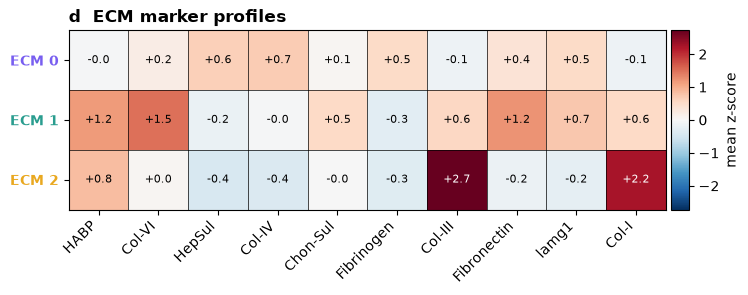

In [8]:
ax = mt.pl.ecm_centroid_heatmap(ecm, ecm_names=MARKERS, K_ecm=K, values="mean_intensity", cluster_colors=ECM,
                                colorbar_label="mean z-score", title="d  ECM marker profiles",
                                figsize=(8, 3.2), show=False)
plt.show()

**Comparison with the paper.** The mean of every marker in every cluster, in pooled z-score units, next to the
paper's panel d.

In [9]:
lh.side_by_side(profiles.T, PAPER["profiles"][MARKERS].T).round(2).rename(columns="ECM {}".format, level=0)

cluster        ECM 0          ECM 1          ECM 2      
            this run paper this run paper this run paper
marker                                                  
HABP           -0.04 -0.04     1.16  1.16     0.85  0.85
Col-VI          0.19  0.19     1.49  1.49     0.04  0.04
HepSul          0.64  0.64    -0.18 -0.18    -0.43 -0.43
Col-IV          0.70  0.70    -0.02 -0.02    -0.40 -0.40
Chon-Sul        0.06  0.06     0.53  0.53    -0.00 -0.00
Fibrinogen      0.52  0.52    -0.28 -0.28    -0.32 -0.32
Col-III        -0.15 -0.15     0.57  0.57     2.72  2.72
Fibronectin     0.38  0.38     1.23  1.23    -0.17 -0.17
lamg1           0.52  0.52     0.73  0.73    -0.25 -0.25
Col-I          -0.13 -0.13     0.55  0.55     2.24  2.24

The paper's workbook holds the patch labels of two ROIs (panels a–c and panels h, i). The table counts the
patches with the same label in this run, joined on the patch.

In [10]:
paper_labels = {GRAPH_ROI: PAPER["graph_patch_labels"], EXAMPLE_ROI: PAPER["example_labels"]["pristine"]}
rows = {}
for roi, paper in paper_labels.items():
    this_run = tables[roi]["ecm_cluster"].astype(int)
    paper = paper.loc[this_run.index]                     # joined on the patch; a missing patch raises an error
    rows[roi] = {"patches": len(this_run), "same label as the paper": int((this_run == paper).sum()),
                 "signal patches, this run": int((this_run >= 0).sum()),
                 "signal patches, paper": int((paper >= 0).sum())}
n_signal = sum(int((labels >= 0).sum()) for labels in LABELS.values())
print(f"Signal patches in the six ROIs: {n_signal:,} (paper: {PAPER['signal_patches']:,})")
pd.DataFrame(rows).T

Signal patches in the six ROIs: 11,435 (paper: 11,435)


,patches,same label as the paper,"signal patches, this run","signal patches, paper"
roi_001,4553,4553,2267,2267
roi_004,4553,4553,1503,1503


## 3. The cell–ECM graph (panels a–c)

`mt.gr.build_cell_ecm_graphs` builds the three layers of the graph in every ROI: cells within 15 pixels of each
other are connected (Squidpy), adjacent patches are connected on an eight-connected grid, and each cell is
linked to its five nearest patches within 15 pixels. This is the reference graph of sections 4 and 5.

In [11]:
graphs = mt.gr.build_cell_ecm_graphs(
    cells, cell_graph="squidpy", cell_radius=(0, 15),
    ecm_edge_method="grid", ecm_grid_connectivity=8,
    cell_ecm_edge_method="knn", cell_ecm_k=5, cell_ecm_Dmax=15, knn_backend="scipy",
)
pd.DataFrame([vars(row) for row in graphs.summaries]).set_index("sample")

,n_nodes,n_cells,n_ecm,cell_cell_edges,ecm_ecm_edges,cell_ecm_edges
sample,,,,,,
roi_001,6373,1820,4553,3029,17805,9046
roi_002,6456,1903,4553,3308,17805,9450
roi_003,6515,1962,4553,3248,17805,9739
roi_004,6495,1942,4553,3861,17805,9639
roi_005,6377,1824,4553,3261,17805,9043
roi_006,6350,1797,4553,2812,17805,8914


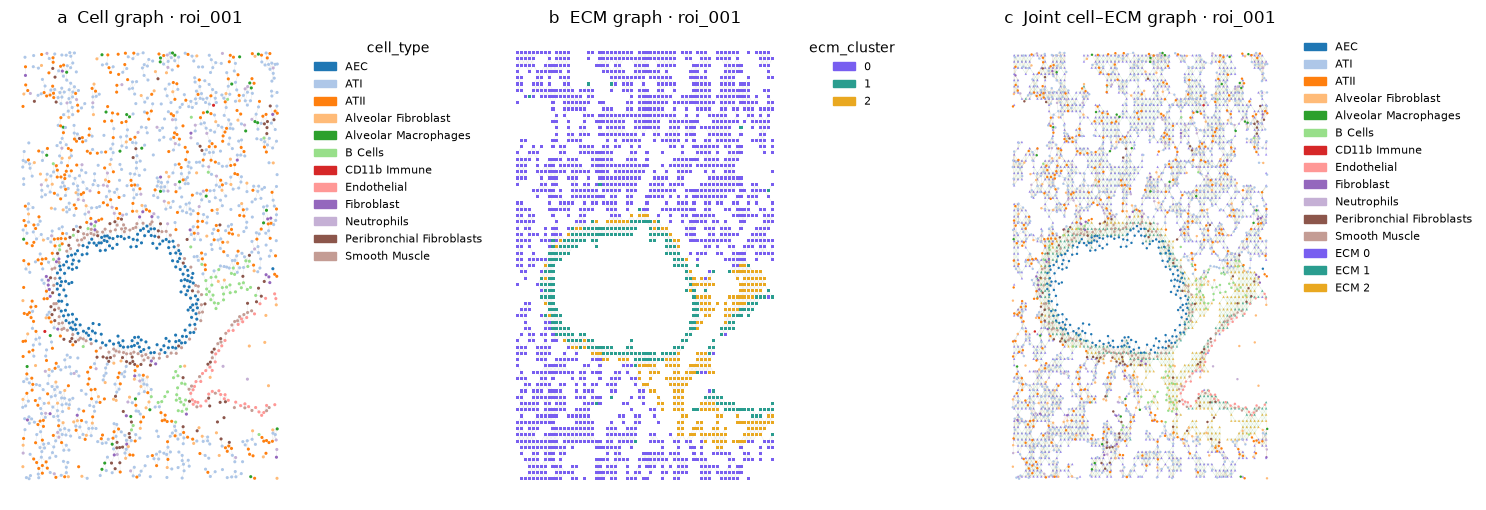

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
style = dict(node_edgecolor=None, node_linewidth=0, ax_off=True, show=False)
cell_colors = [plt.matplotlib.colors.to_hex(color) for color in plt.get_cmap("tab20").colors]   # one per cell type
mt.pl.cell_graph(cells[GRAPH_ROI], node_size=5, edge_alpha=0.3, edge_width=0.3, palette=cell_colors,
                 ax=axes[0], **style)
mt.pl.ecm_graph(cells[GRAPH_ROI], node_size=5, node_marker="s", edge_alpha=0.3, edge_width=0.3,
                palette=ECM, ax=axes[1], **style)
mt.pl.cell_ecm_graph(cells[GRAPH_ROI], node_size_cell=3, node_size_ecm=3, edge_alpha=0.2, edge_width=0.3,
                     cell_palette=cell_colors, ecm_palette=ECM, ax=axes[2], **style)
for ax, title in zip(axes, ["a  Cell graph", "b  ECM graph", "c  Joint cell–ECM graph"]):
    ax.set_title(f"{title} · {GRAPH_ROI}")
plt.tight_layout()
plt.show()

**Comparison with the paper.** Background patches stay in the graph as unlabelled nodes, and the paper leaves
them out of all counts. The counts below follow that rule: ECM–ECM edges between two signal patches and
cell–ECM edges that end on a signal patch. `mt.gr.graph_layers` returns the layers as sparse matrices.

In [13]:
layers = mt.gr.graph_layers(cells[GRAPH_ROI])
signal = LABELS[GRAPH_ROI] >= 0
graph_counts = pd.Series({
    "cells": cells[GRAPH_ROI].n_obs,
    "cell-cell edges": sparse.triu(layers.cell, k=1).nnz,
    "ECM-ECM edges": sparse.triu(layers.ecm[signal][:, signal], k=1).nnz,
    "cell-ECM edges": layers.cell_ecm[:, signal].nnz,
})
lh.side_by_side(graph_counts, PAPER["graph"])

,this run,paper
cells,1820,1820
cell-cell edges,3029,3029
ECM-ECM edges,6042,6042
cell-ECM edges,6200,6200


## 4. The ECM cluster that AECs contact (panel e)

`mt.tl.cell_ecm_enrichment` counts the AEC–ECM edges that end on each ECM cluster and compares the count with
the one expected from the share of all cell–ECM edges that end on that cluster. Observed and expected counts
are summed over the ROIs (`pooled`) and also kept per ROI (`per_roi`). `n_perm=0` skips the permutation test,
which the paper does not use here. `mt.pl.cell_ecm_enrichment_bars` draws the pooled ratio as bars and the ROIs
as points; a ROI without an AEC edge to a cluster has no ratio and is drawn as an open grey marker.

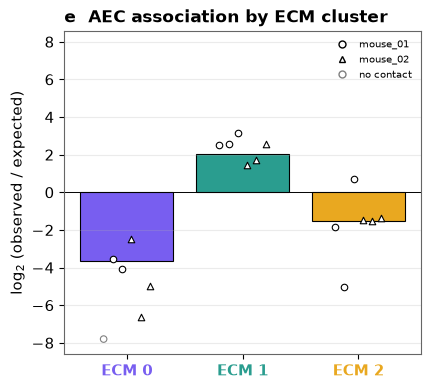

,n_obs,n_exp,log2_enr
cluster,,,
0,151,1908.322,-3.660
1,2505,603.732,2.053
2,75,218.945,-1.546


In [14]:
association = mt.tl.cell_ecm_enrichment(cells, CELL_TYPE, K_ecm=K, n_perm=0, random_state=SEED, return_details=True)
ax = mt.pl.cell_ecm_enrichment_bars(association, annotate="none", show_samples=True, sample_groups=mouse,
                                    cluster_colors=ECM, title="e  AEC association by ECM cluster",
                                    figsize=(4.6, 4.2), show=False)
plt.show()
association.pooled.set_index("cluster")[["n_obs", "n_exp", "log2_enr"]].round(3)

**Comparison with the paper.** The pooled log2 ratio of observed to expected edges, then the ratio of every
ROI, then the number of ROIs with a positive and with a negative ratio.

In [15]:
lh.side_by_side(association.pooled.set_index("cluster")["log2_enr"], PAPER["association_pooled"]).round(3)

,this run,paper
cluster,,
0,-3.660,-3.660
1,2.053,2.053
2,-1.546,-1.546


In [16]:
per_roi = association.per_roi.assign(log2_enr=lambda t: t["log2_enr"].where(t["n_obs"] > 0))   # no edge, no ratio
ratio = per_roi.pivot(index="roi", columns="cluster", values="log2_enr")
lh.side_by_side(ratio, PAPER["association"]).round(2).rename(columns="ECM {}".format, level=0)

cluster    ECM 0          ECM 1          ECM 2      
        this run paper this run paper this run paper
roi                                                 
roi_001      NaN   NaN     2.51  2.51    -1.82 -1.82
roi_002    -3.52 -3.52     2.57  2.57    -5.02 -5.02
roi_003    -4.07 -4.07     3.13  3.13     0.72  0.72
roi_004    -2.48 -2.48     1.45  1.45    -1.48 -1.48
roi_005    -6.61 -6.61     1.70  1.70    -1.52 -1.52
roi_006    -4.97 -4.97     2.59  2.59    -1.35 -1.35

In [17]:
def signs(table):
    return pd.DataFrame({"positive": (table > 0).sum(), "negative": (table < 0).sum(),
                         "no AEC edge": table.isna().sum()})

lh.side_by_side(signs(ratio), signs(PAPER["association"])).rename(index="ECM {}".format)

positive       negative       no AEC edge      
        this run paper this run paper    this run paper
cluster                                                
ECM 0          0     0        5     5           1     1
ECM 1          6     6        0     0           0     0
ECM 2          1     1        5     5           0     0

## 5. The markers that AECs contact inside ECM 1 (panels f, g)

`mt.tl.cell_ecm_marker_contrast` compares, within the bronchovascular-wall cluster (`cluster=WALL`), the
patches that have an edge to an AEC with those that have none. In each ROI the mean marker profile of the
patches without an AEC edge is subtracted from that of the patches with one, and the six ROIs are averaged with
equal weight. `weighting="unique_patch"` counts each patch once, however many AECs it is linked to, and
`accumulation_dtype="input"` keeps the sums in the precision of the stored patch features, as in the paper's
analysis.

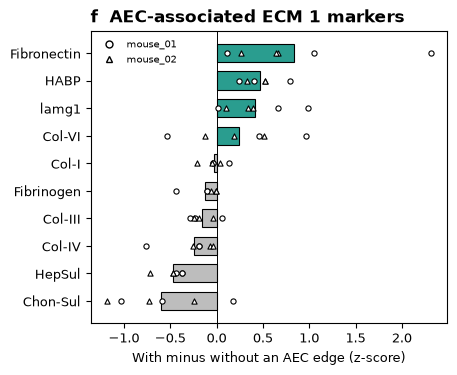

,n_contacted,n_uncontacted
sample,,
roi_001,142,132
roi_002,153,156
roi_003,109,67
roi_004,268,50
roi_005,156,77
roi_006,126,43


In [18]:
contrast = mt.tl.cell_ecm_marker_contrast(cells, CELL_TYPE, cluster=WALL, ecm_names=MARKERS,
                                          weighting="unique_patch", accumulation_dtype="input")
ax = mt.pl.marker_contrast_bars(contrast, color=ECM[WALL], sample_groups=mouse,
                                xlabel="With minus without an AEC edge (z-score)",
                                title="f  AEC-associated ECM 1 markers", figsize=(4.6, 3.8), show=False)
plt.show()
contrast.counts

**Comparison with the paper.** The mean difference of every marker over the six ROIs, the largest difference of
a single ROI value from the paper, and the markers whose difference has the same sign in all six ROIs.

In [19]:
order = contrast.mean.sort_values().index
difference = (contrast.per_sample.loc[ROIS, MARKERS] - PAPER["contrast"].loc[ROIS, MARKERS]).abs().to_numpy().max()
print(f"Largest difference of a per-ROI value from the paper: {difference:.3f}")
for name, table in (("this run", contrast.per_sample), ("paper", PAPER["contrast"])):
    same_sign = [marker for marker in order if table[marker].gt(0).all() or table[marker].lt(0).all()]
    print(f"Same sign in all six ROIs, {name}: {', '.join(same_sign)}")
lh.side_by_side(contrast.mean[order], PAPER["contrast_mean"]).round(3)

Largest difference of a per-ROI value from the paper: 0.000
Same sign in all six ROIs, this run: HepSul, Col-IV, Fibrinogen, lamg1, HABP, Fibronectin
Same sign in all six ROIs, paper: HepSul, Col-IV, Fibrinogen, lamg1, HABP, Fibronectin


,this run,paper
marker,,
Chon-Sul,-0.600,-0.600
HepSul,-0.473,-0.473
Col-IV,-0.248,-0.248
Col-III,-0.155,-0.155
Fibrinogen,-0.120,-0.120
Col-I,-0.024,-0.024
Col-VI,0.243,0.243
lamg1,0.417,0.417
HABP,0.469,0.469


Panel g shows the fibronectin image of one ROI with the ECM 1 patches that have an AEC edge
(`contrast.contacted`) tinted green and the AECs in red. `lh.draw_contacted_patches` draws it; the image is
smoothed and scaled for display only.

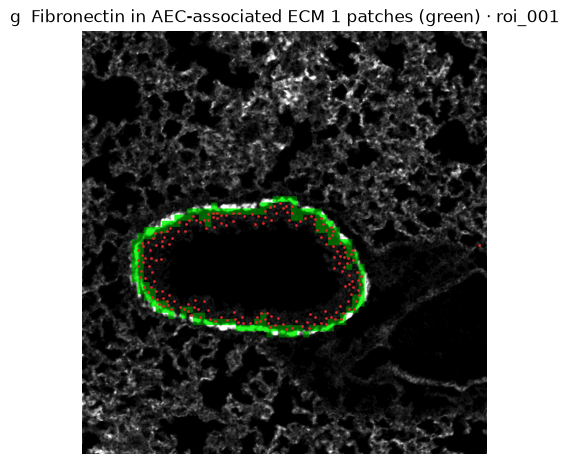

,patches
this run,142
paper,142
in both,142


In [20]:
kept = bundle.panel.loc[bundle.panel["keep"].eq(1)].reset_index(drop=True)     # the channels of the image stack
channel = int(kept.index[kept["name"].eq("Fibronectin")][0])
contacted = contrast.contacted[GRAPH_ROI]                                      # ECM 1 patches with an AEC edge
aec = cells[GRAPH_ROI].obs["cell_type"].astype(str).eq(CELL_TYPE).to_numpy()

fig, ax = plt.subplots(figsize=(5.5, 5.5))
lh.draw_contacted_patches(ax, bundle.images[GRAPH_ROI][channel], XY[GRAPH_ROI][contacted.to_numpy()],
                          np.asarray(cells[GRAPH_ROI].obsm["spatial"])[aec], patch_size=PATCH_SIZE,
                          title=f"g  Fibronectin in AEC-associated ECM 1 patches (green) · {GRAPH_ROI}")
plt.show()

this_run, paper = set(contacted.index[contacted]), set(PAPER["contacted_patches"])
pd.Series({"this run": len(this_run), "paper": len(paper), "in both": len(this_run & paper)}).to_frame("patches")

## 6. Recovery of corrupted ECM labels from context (panels h–j)

This section asks whether the cells around a patch say which ECM cluster the patch belongs to. Some ECM labels
are replaced by wrong ones, and a classifier that sees only the surroundings of each patch has to find and
correct them.

**Corruption.** `mt.tl.corrupt_labels` replaces 10% of the signal-patch labels of a ROI, half inside square
blocks of side 50, 100 or 150 pixels and half as isolated patches. Every ROI is corrupted five times with
different seeds.

In [21]:
corruptions = {
    (roi, realisation): mt.tl.corrupt_labels(
        LABELS[roi], XY[roi], fraction=0.10, block_fraction=0.5, block_sides=(50, 100, 150),
        min_block_units=20, categories=range(K), random_state=realisation * 1000 + i,
    )
    for i, roi in enumerate(ROIS) for realisation in range(N_REALISATIONS)
}
example = corruptions[(EXAMPLE_ROI, 0)]          # the corruption drawn in panels h and i
print(f"{EXAMPLE_ROI}, realisation 0: {int(example.is_corrupted.sum())} of {int((LABELS[EXAMPLE_ROI] >= 0).sum())} "
      f"signal labels replaced, {int((example.is_corrupted & example.in_block()).sum())} of them inside a block")
example.blocks

roi_004, realisation 0: 150 of 1503 signal labels replaced, 76 of them inside a block


,centre_x,centre_y,side,new_label,n_replaced
0,155.521576,100.19117,150.0,2,75


**Comparison with the paper.** The corruption is seeded, so it can be checked exactly: the paper's own
uncorrupted labels of this ROI, corrupted here with the same seed, must give the paper's corrupted labels.

In [22]:
paper_example = PAPER["example_labels"]
check = mt.tl.corrupt_labels(
    paper_example["pristine"].to_numpy(int), paper_example[["x", "y"]].to_numpy(float), fraction=0.10,
    block_fraction=0.5, block_sides=(50, 100, 150), min_block_units=20, categories=range(K),
    random_state=0 * 1000 + ROIS.index(EXAMPLE_ROI),
)
same = int((check.labels == paper_example["observed"].to_numpy(int)).sum())
print(f"Corrupted labels equal to the paper's: {same:,} of {len(paper_example):,} patches")
lh.side_by_side(check.blocks.iloc[0], PAPER["example_blocks"].iloc[0])

Corrupted labels equal to the paper's: 4,553 of 4,553 patches


,this run,paper
centre_x,155.521576,155.521576
centre_y,100.191170,100.191170
side,150.000000,150.000000
new_label,2.000000,2.000000
n_replaced,75.000000,75.000000


**The selected settings.** Each mouse is held out in turn. The classifier is fitted on the three uncorrupted
ROIs of the other mouse and applied to the corrupted ROIs of the held-out mouse. Three kinds of context are
compared: the cells linked to a patch (**cell**), its neighbouring patches (**ECM**), or both (**joint**). The
graph, the features, the classifier and the relabelling rule of each were selected in the paper within the
training mouse (Supplementary Table 6). The table lists the main ones; `lung_selected.json` holds all of them.

In [23]:
def describe(setting):
    graph, clean = setting["graph"], setting["cleaning"]
    return {"cell-cell edges": graph["cc_rule"], "ECM-ECM edges": graph["ee_rule"], "cell-ECM edges": graph["ce_rule"],
            "edge weight": graph["edge_weight"], "hops": setting["features"]["hops"],
            "features": setting["features"]["composition_norm"], "penalty": setting["learner"]["penalty"],
            "anomaly score": clean["anomaly_stat"], "threshold": round(clean["threshold"], 3),
            "passes": clean["passes"], "calibration": setting["calibration"]}

pd.DataFrame({(held_out, context): describe(SETTINGS[held_out][context]["config"])
              for held_out in sorted(SETTINGS) for context in CONTEXTS}).T.rename_axis(["held-out mouse", "context"])

cell-cell edges ECM-ECM edges cell-ECM edges  \
held-out mouse context                                                
mouse_01       cell             radius         grid8         radius   
               joint          delaunay           knn       delaunay   
               ecm              radius           knn       delaunay   
mouse_02       cell           delaunay         grid8            knn   
               joint            radius      delaunay         radius   
               ecm              radius        radius            knn   

                            edge weight hops  features     penalty  \
held-out mouse context                                               
mouse_01       cell     gaussian_median    1     count  elasticnet   
               joint               none    2     count          l2   
               ecm                inv_d    2  fraction        none   
mouse_02       cell               inv_d    2  fraction          l1   
               joint              inv_d    1  fraction          l2   
               ecm                 none    2  fraction          l2   

                         anomaly score threshold passes  calibration  
held-out mouse context                                                
mouse_01       cell        raw_neglogp     2.992      1         none  
               joint    minmax_neglogp      0.36      3         none  
               ecm         raw_neglogp     2.822      2  temperature  
mouse_02       cell        one_minus_p      0.95      1         none  
               joint       one_minus_p     0.943      3         none  
               ecm      minmax_neglogp     0.519      1  temperature

### One case, step by step

The cell context with mouse 2 held out, for the corruption of `roi_004` drawn in panels h and i. The same
calls are then run for every case by `lh.evaluate_setting`.

**Graph.** The graph of this setting is built on copies of the ROIs, so the reference graph of sections 3 to 5
stays in `cells`. Cells are connected by a Delaunay triangulation, patches on the eight-connected grid, and
each cell is linked to its nine nearest patches within 20 pixels.

In [24]:
held_out = mouse[EXAMPLE_ROI]
setting = SETTINGS[held_out]["cell"]["config"]
train = [roi for roi in ROIS if mouse[roi] != held_out]

graph_arguments = dict(
    cell_graph="mantpy", cell_edge_method="delaunay",
    ecm_edge_method="grid", ecm_grid_connectivity=8,
    cell_ecm_edge_method="knn", cell_ecm_k=9, cell_ecm_Dmax=20.0,
    knn_backend="scipy", delaunay_jitter=1e-6, delaunay_seed=0,
)
assert graph_arguments == lh.graph_options(setting["graph"]), "the arguments written here are the selected ones"

case = {roi: cells[roi].copy() for roi in ROIS}
for adata in case.values():                      # Squidpy's cell graph of section 3; Mantpy builds this setting's
    del adata.obsp["spatial_connectivities"], adata.obsp["spatial_distances"]
case_graphs = mt.gr.build_cell_ecm_graphs(case, **graph_arguments)
print(f"held-out mouse: {held_out}; training ROIs: {', '.join(train)}")
pd.DataFrame([vars(row) for row in case_graphs.summaries]).set_index("sample")

held-out mouse: mouse_02; training ROIs: roi_001, roi_002, roi_003


,n_nodes,n_cells,n_ecm,cell_cell_edges,ecm_ecm_edges,cell_ecm_edges
sample,,,,,,
roi_001,6373,1820,4553,5441,17805,16209
roi_002,6456,1903,4553,5691,17805,16960
roi_003,6515,1962,4553,5865,17805,17482
roi_004,6495,1942,4553,5799,17805,17323
roi_005,6377,1824,4553,5449,17805,16235
roi_006,6350,1797,4553,5365,17805,15996


**Context features.** `mt.tl.context_features` describes every patch by what is around it in the graph, and
never by the patch's own label. For the cell context these are the cell types within two steps of the patch,
weighted by inverse distance and given as proportions. The ECM and joint contexts also use the labels of the
neighbouring patches, which are passed as `ecm_labels`.

**Classifier.** A multinomial logistic regression (scikit-learn) is fitted on the signal patches of the three
training ROIs, with their uncorrupted labels. `lh.fit_classifier` applies the selected penalty and
standardisation and returns a function that gives the probability of each cluster.

In [25]:
feature_arguments = dict(context="cell", hops=2, normalization="proportions", edge_weight="inverse",
                         cell_categories=CELL_TYPES, ecm_categories=range(K))
assert feature_arguments == lh.feature_options(setting, CELL_TYPES, K)

def patch_context(roi, labels):
    return mt.tl.context_features(case[roi], ecm_labels=labels, **feature_arguments)

X_train = np.vstack([patch_context(roi, LABELS[roi]).to_numpy()[LABELS[roi] >= 0] for roi in train])
y_train = np.concatenate([LABELS[roi][LABELS[roi] >= 0] for roi in train])
predict = lh.fit_classifier(X_train, y_train, setting["learner"], seed=SEED)
print(f"{X_train.shape[0]:,} training patches, {X_train.shape[1]} features")
patch_context(EXAMPLE_ROI, example.labels).loc[LABELS[EXAMPLE_ROI] >= 0].head(3).round(3)

7,150 training patches, 24 features


,cell:AEC,cell:ATI,cell:ATII,cell:Alveolar Fibroblast,cell:Alveolar Macrophages,cell:B Cells,cell:CD11b Immune,cell:Endothelial,cell:Fibroblast,cell:Neutrophils,...,cell.cell:ATII,cell.cell:Alveolar Fibroblast,cell.cell:Alveolar Macrophages,cell.cell:B Cells,cell.cell:CD11b Immune,cell.cell:Endothelial,cell.cell:Fibroblast,cell.cell:Neutrophils,cell.cell:Peribronchial Fibroblasts,cell.cell:Smooth Muscle
2,0.0,0.201,0.622,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.457,0.020,0.0,0.0,0.0,0.0,0.0,0.0,0.124,0.0
3,0.0,0.906,0.094,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.311,0.005,0.0,0.0,0.0,0.0,0.0,0.0,0.136,0.0
4,0.0,1.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.048,0.011,0.0,0.0,0.0,0.0,0.0,0.0,0.025,0.0


**Detection.** `mt.tl.label_anomaly_scores` gives every patch the score −log P(observed label | context): a
label that the context makes unlikely gets a high score. With `prior=`, the probability is first divided by the
frequency of the label in the training ROIs, which removes what label frequency alone explains (a rare label is
not suspicious for being rare).

**Relabelling.** `mt.tl.reconstruct_labels_iteratively` relabels a patch with the most probable cluster when
its anomaly score exceeds the selected threshold, and repeats this for the selected number of passes, each time
with the context computed from the current labels. This setting uses one pass and the score 1 − P.

**Scores.** `mt.tl.score_label_reconstruction` compares the uncorrupted, corrupted and reconstructed labels,
and scores how well the anomaly scores separate the replaced labels from the others (ROC-AUC).

In [26]:
observed = example.labels
probabilities = predict(patch_context(EXAMPLE_ROI, observed).to_numpy())
prior = np.bincount(y_train, minlength=K) / len(y_train)          # label frequencies of the training ROIs
anomaly = {
    "raw": mt.tl.label_anomaly_scores(observed, probabilities, categories=range(K)),
    "prior_adjusted": mt.tl.label_anomaly_scores(observed, probabilities, categories=range(K), prior=prior),
}
clean = setting["cleaning"]
result = mt.tl.reconstruct_labels_iteratively(
    observed, lambda labels: predict(patch_context(EXAMPLE_ROI, labels).to_numpy()),
    threshold=clean["threshold"], max_passes=1, score="one_minus_p", categories=range(K),
)
scored = mt.tl.score_label_reconstruction(LABELS[EXAMPLE_ROI], observed, result.labels,
                                          corrupted=example.is_corrupted, scores=anomaly, categories=range(K))
pd.Series(scored.metrics).round(4).to_frame(f"{EXAMPLE_ROI}, realisation 0")

,"roi_004, realisation 0"
n_signal,1503.0000
n_artifact,150.0000
n_relabelled,143.0000
corrupted_fraction,0.0998
before_accuracy,0.9002
after_accuracy,0.9508
artifact_recovered,0.7200
correction_precision,0.7552
pristine_relabel_rate,0.0237
roc_auc_raw,0.9690


### All cases

`lh.evaluate_setting` runs the calls above for one held-out mouse and one context: it builds the graph of the
setting, computes the context features, fits the classifier on the other mouse, and scores and relabels every
corruption of the held-out ROIs. `lh.score_label_prior` gives the baseline in which every patch gets the label
frequencies of the training mouse, so the score only says how rare the observed label is. The last lines check
that the case shown above is the same as the helper's.

In [27]:
score_tables, class_tables, reconstructed = [], [], {}
for held_out in sorted(mouse.unique()):
    score_tables.append(lh.score_label_prior(cells, corruptions, held_out=held_out, mouse=mouse, n_clusters=K))
    for context in CONTEXTS:
        scores, per_class, maps = lh.evaluate_setting(
            cells, corruptions, SETTINGS[held_out][context]["config"],
            held_out=held_out, mouse=mouse, cell_types=CELL_TYPES, n_clusters=K, seed=SEED,
        )
        score_tables.append(scores)
        class_tables.append(per_class)
        reconstructed.update({(context, roi, realisation): labels for (roi, realisation), labels in maps.items()})
results = pd.concat(score_tables, ignore_index=True)       # one row per context, ROI and realisation
classes = pd.concat(class_tables, ignore_index=True)       # the same, per ECM cluster

row = results.query("context == 'cell' and roi == @EXAMPLE_ROI and realisation == 0").iloc[0]
assert all(np.isclose(row[name], value) for name, value in scored.metrics.items()), "the case shown above"
assert np.array_equal(reconstructed[("cell", EXAMPLE_ROI, 0)], result.labels)
print(f"{len(results)} rows: {results.groupby('context').size().to_dict()}")

120 rows: {'cell': 30, 'ecm': 30, 'joint': 30, 'prior': 30}


Panels h and i show the held-out ROI before the corruption, with 10% of its labels replaced, and after the
reconstruction from cell context. `mt.pl.patch_map` draws the labels; `lh.mark_corruption` outlines the
replaced block and rings the isolated replaced patches.

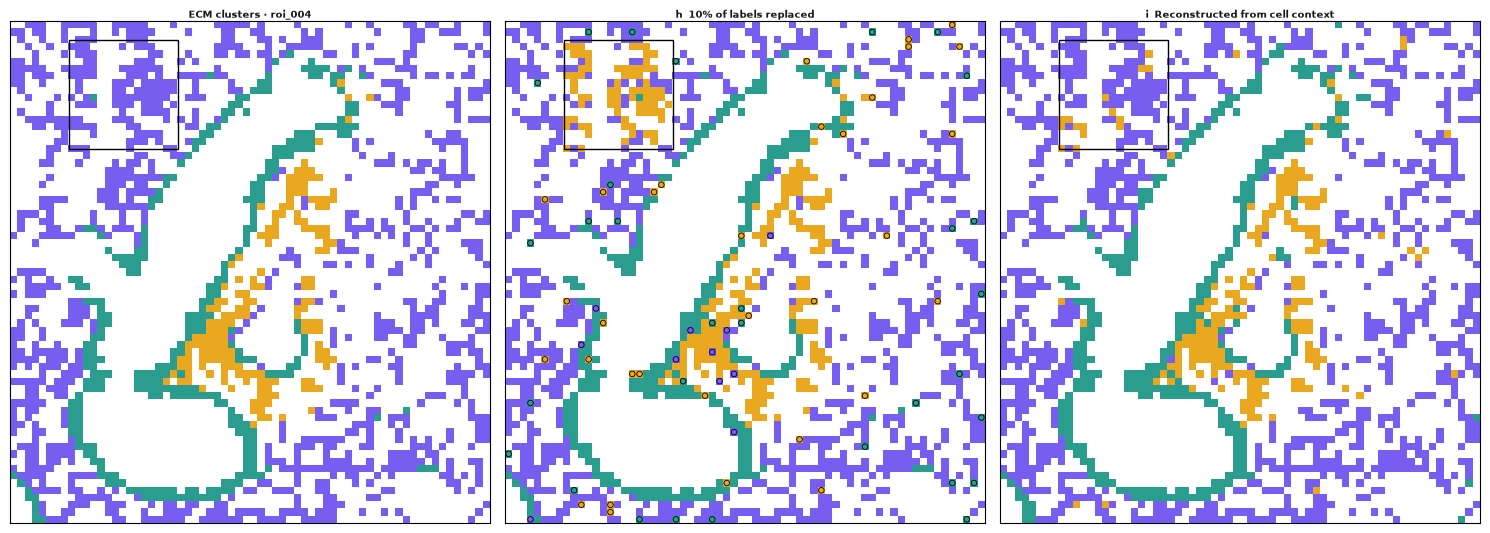

In [28]:
maps = [(LABELS[EXAMPLE_ROI], f"ECM clusters · {EXAMPLE_ROI}"),
        (example.labels, "h  10% of labels replaced"),
        (reconstructed[("cell", EXAMPLE_ROI, 0)], "i  Reconstructed from cell context")]
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
for ax, (labels, title) in zip(axes, maps):
    mt.pl.patch_map(tables[EXAMPLE_ROI], labels, patch_size=PATCH_SIZE, palette=ECM, ax=ax,
                    shape=(69, 66), extent=(0, 660, 690, 0), title=title)
    lh.mark_corruption(ax, example, isolated=ax is axes[1])
plt.tight_layout()
plt.show()

**Comparison with the paper.** The paper's workbook holds the uncorrupted, corrupted and reconstructed labels of
this ROI. They are scored here with the same Mantpy function, next to this run.

In [29]:
paper_scored = mt.tl.score_label_reconstruction(
    paper_example["pristine"].to_numpy(int), paper_example["observed"].to_numpy(int),
    paper_example["cleaned"].to_numpy(int), corrupted=paper_example["is_artifact"].to_numpy(bool),
    categories=range(K),
).metrics
names = {"n_signal": "signal patches", "n_artifact": "replaced labels", "n_relabelled": "labels changed",
         "before_accuracy": "label accuracy before", "after_accuracy": "label accuracy after",
         "artifact_recovered": "replaced labels corrected", "pristine_relabel_rate": "uncorrupted labels made wrong"}
paper_cleaned = paper_example["cleaned"].loc[tables[EXAMPLE_ROI].index].to_numpy(int)      # joined on the patch
same = int((reconstructed[("cell", EXAMPLE_ROI, 0)] == paper_cleaned).sum())
print(f"Reconstructed labels equal to the paper's: {same:,} of {len(paper_cleaned):,} patches")
example_scores = lh.side_by_side(pd.Series({label: row[key] for key, label in names.items()}),
                                 pd.Series({label: paper_scored[key] for key, label in names.items()}))
example_scores.round(4)

Reconstructed labels equal to the paper's: 4,553 of 4,553 patches


,this run,paper
signal patches,1503.0000,1503.0000
replaced labels,150.0000,150.0000
labels changed,143.0000,143.0000
label accuracy before,0.9002,0.9002
label accuracy after,0.9508,0.9508
replaced labels corrected,0.7200,0.7200
uncorrupted labels made wrong,0.0237,0.0237


Panel j shows how well each context detects the replaced labels. The scores are averaged over the five
realisations within each ROI, and the bars are the means over the six ROIs. Open markers use the raw anomaly
score and filled markers the prior-adjusted one; the dashed line is the label-prior baseline.

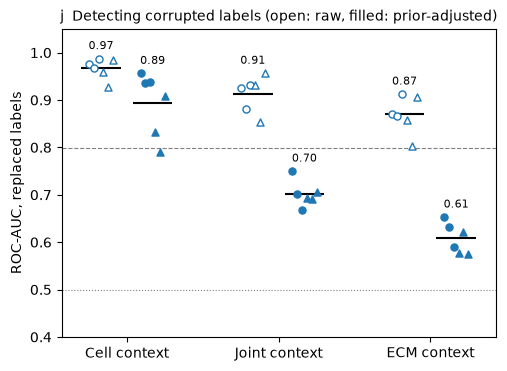

In [30]:
columns = ["roc_auc_raw", "roc_auc_prior_adjusted"]
per_roi_scores = results.groupby(["context", "roi"])[columns].mean()          # mean over the realisations
prior_level = per_roi_scores.xs("prior")["roc_auc_raw"].mean()

fig, ax = plt.subplots(figsize=(5.6, 4))
lh.draw_detection(ax, per_roi_scores, mouse, contexts=CONTEXTS, names=CONTEXT_NAMES, prior_level=prior_level,
                  markers=MOUSE_MARK)
ax.set_title("j  Detecting corrupted labels (open: raw, filled: prior-adjusted)", fontsize=10)
plt.show()

**Comparison with the paper.** The ROC-AUC of every context, as the mean over the six ROIs and for every ROI.
The label prior has no prior-adjusted score.

In [31]:
order = CONTEXTS + ["prior"]
lh.side_by_side(per_roi_scores.groupby("context").mean().loc[order],
                PAPER["detection"].groupby("context").mean()).round(3)

roc_auc_raw        roc_auc_prior_adjusted       
           this run  paper               this run  paper
context                                                 
cell          0.967  0.967                  0.894  0.894
joint         0.913  0.913                  0.702  0.702
ecm           0.870  0.869                  0.608  0.608
prior         0.800  0.800                    NaN    NaN

In [32]:
adjusted = per_roi_scores["roc_auc_prior_adjusted"].unstack("context")[CONTEXTS]
first = int((adjusted.idxmax(axis=1) == "cell").sum())
print(f"ROIs in which cell context has the highest prior-adjusted ROC-AUC: {first} of {len(adjusted)} (paper: 6 of 6)")
lh.side_by_side(per_roi_scores.loc[order], PAPER["detection"]).round(3)

ROIs in which cell context has the highest prior-adjusted ROC-AUC: 6 of 6 (paper: 6 of 6)


roc_auc_raw        roc_auc_prior_adjusted       
                   this run  paper               this run  paper
context roi                                                     
cell    roi_001       0.976  0.976                  0.956  0.956
        roi_002       0.967  0.967                  0.936  0.936
        roi_003       0.988  0.988                  0.937  0.937
        roi_004       0.958  0.958                  0.833  0.833
        roi_005       0.928  0.928                  0.791  0.791
        roi_006       0.985  0.985                  0.909  0.909
joint   roi_001       0.925  0.925                  0.750  0.750
        roi_002       0.882  0.882                  0.702  0.702
        roi_003       0.931  0.931                  0.669  0.669
        roi_004       0.931  0.931                  0.694  0.694
        roi_005       0.853  0.853                  0.690  0.690
        roi_006       0.957  0.957                  0.705  0.705
ecm     roi_001       0.871  0.870                  0.653  0.653
        roi_002       0.867  0.866                  0.631  0.630
        roi_003       0.913  0.913                  0.590  0.592
        roi_004       0.858  0.858                  0.577  0.577
        roi_005       0.804  0.804                  0.620  0.620
        roi_006       0.905  0.905                  0.575  0.575
prior   roi_001       0.801  0.801                    NaN    NaN
        roi_002       0.785  0.785                    NaN    NaN
        roi_003       0.921  0.921                    NaN    NaN
        roi_004       0.804  0.804                    NaN    NaN
        roi_005       0.657  0.657                    NaN    NaN
        roi_006       0.830  0.830                    NaN    NaN

The relabelling from cell context, next to the values stated in the paper's text. Each value is a mean over
the five realisations within each ROI and then over the six ROIs; the per-cluster values are the share of the
replaced labels of that cluster that were corrected.

In [33]:
cell = results[results["context"].eq("cell")].groupby("roi").mean(numeric_only=True)       # mean over the realisations
corrected = classes[classes["context"].eq("cell")].groupby(["roi", "cluster"])[["n_corrupted", "n_restored"]].sum()
corrected = (corrected["n_restored"] / corrected["n_corrupted"]).groupby("cluster").mean()
text_values = pd.Series({
    "replaced labels corrected, mean": cell["artifact_recovered"].mean(),
    "replaced labels corrected, lowest ROI": cell["artifact_recovered"].min(),
    "replaced labels corrected, highest ROI": cell["artifact_recovered"].max(),
    "uncorrupted labels made wrong": cell["pristine_relabel_rate"].mean(),
    "label accuracy before": cell["before_accuracy"].mean(),
    "label accuracy after": cell["after_accuracy"].mean(),
    "corrected, ECM 0 (alveolar)": corrected[0],
    "corrected, ECM 1 (bronchovascular wall)": corrected[1],
    "corrected, ECM 2 (adventitial)": corrected[2],
})
print(f"Notebook elapsed: {(time.perf_counter() - STARTED) / 60:.1f} min")
lh.side_by_side(text_values, PAPER["text"]).round(3)

Notebook elapsed: 1.0 min


,this run,paper
"replaced labels corrected, mean",0.700,0.700
"replaced labels corrected, lowest ROI",0.524,0.520
"replaced labels corrected, highest ROI",0.776,0.780
uncorrupted labels made wrong,0.021,0.021
label accuracy before,0.900,0.900
label accuracy after,0.951,0.950
"corrected, ECM 0 (alveolar)",0.795,0.800
"corrected, ECM 1 (bronchovascular wall)",0.481,0.480
"corrected, ECM 2 (adventitial)",0.333,0.330


## 7. Paper and notebook results

The table puts the paper's values beside the values computed in this notebook, panel by panel. The paper's
values are read from its source data (`source_data/fig4.xlsx`). The number of signal patches and the last block
are taken from the paper's text, which rounds the fractions to two decimals.

In [34]:
COUNT, DECIMAL = "{:,.0f}", "{:.3f}"
ecm = "ECM {}".format
context_names = {**CONTEXT_NAMES, "prior": "Label prior"}
detection = per_roi_scores.groupby("context").mean().loc[CONTEXTS + ["prior"]].rename(index=context_names)
paper_detection = PAPER["detection"].groupby("context").mean().rename(index=context_names)

parts = [   # heading, this run, paper, number format
    (f"a–c: graph of {GRAPH_ROI}", graph_counts, PAPER["graph"], COUNT),
    ("d: ECM signal patches", {"six ROIs": n_signal}, {"six ROIs": PAPER["signal_patches"]}, COUNT),
    (f"e: {CELL_TYPE} association, pooled log2 enrichment",
     association.pooled.set_index("cluster")["log2_enr"].rename(ecm), PAPER["association_pooled"].rename(ecm), DECIMAL),
    (f"f: markers of ECM {WALL} patches, with minus without an {CELL_TYPE} edge",
     contrast.mean.sort_values(), PAPER["contrast_mean"], DECIMAL),
    (f"g: {GRAPH_ROI}", {f"ECM {WALL} patches with an {CELL_TYPE} edge": contacted.sum()},
     {f"ECM {WALL} patches with an {CELL_TYPE} edge": len(PAPER["contacted_patches"])}, COUNT),
    (f"h, i: {EXAMPLE_ROI}, numbers of patches", example_scores["this run"].iloc[:3], example_scores["paper"].iloc[:3], COUNT),
    (f"h, i: {EXAMPLE_ROI}, fractions", example_scores["this run"].iloc[3:], example_scores["paper"].iloc[3:], DECIMAL),
    ("j: mean ROC-AUC, raw", detection["roc_auc_raw"], paper_detection["roc_auc_raw"], DECIMAL),
    ("j: mean ROC-AUC, prior-adjusted", detection["roc_auc_prior_adjusted"].dropna(),
     paper_detection["roc_auc_prior_adjusted"].dropna(), DECIMAL),
    ("Text: relabelling from cell context", text_values, PAPER["text"], DECIMAL),
]
pd.concat({heading: lh.side_by_side(pd.Series(this_run), pd.Series(paper))[["paper", "this run"]].map(form.format)
           for heading, this_run, paper, form in parts}, names=["panel", "result"])

paper  \
panel                                              result                                            
a–c: graph of roi_001                              cells                                     1,820   
                                                   cell-cell edges                           3,029   
                                                   ECM-ECM edges                             6,042   
                                                   cell-ECM edges                            6,200   
d: ECM signal patches                              six ROIs                                 11,435   
e: AEC association, pooled log2 enrichment         ECM 0                                    -3.660   
                                                   ECM 1                                     2.053   
                                                   ECM 2                                    -1.546   
f: markers of ECM 1 patches, with minus without... Chon-Sul                                 -0.600   
                                                   HepSul                                   -0.473   
                                                   Col-IV                                   -0.248   
                                                   Col-III                                  -0.155   
                                                   Fibrinogen                               -0.120   
                                                   Col-I                                    -0.024   
                                                   Col-VI                                    0.243   
                                                   lamg1                                     0.417   
                                                   HABP                                      0.469   
                                                   Fibronectin                               0.840   
g: roi_001                                         ECM 1 patches with an AEC edge              142   
h, i: roi_004, numbers of patches                  signal patches                            1,503   
                                                   replaced labels                             150   
                                                   labels changed                              143   
h, i: roi_004, fractions                           label accuracy before                     0.900   
                                                   label accuracy after                      0.951   
                                                   replaced labels corrected                 0.720   
                                                   uncorrupted labels made wrong             0.024   
j: mean ROC-AUC, raw                               Cell context                              0.967   
                                                   Joint context                             0.913   
                                                   ECM context                               0.869   
                                                   Label prior                               0.800   
j: mean ROC-AUC, prior-adjusted                    Cell context                              0.894   
                                                   Joint context                             0.702   
                                                   ECM context                               0.608   
Text: relabelling from cell context                replaced labels corrected, mean           0.700   
                                                   replaced labels corrected, lowest ROI     0.520   
                                                   replaced labels corrected, highest ROI    0.780   
                                                   uncorrupted labels made wrong             0.021   
                                                   label accuracy before                     0.900   
             

[Mantpy](https://github.com/moeghaf/Mantpy) · [dataset](https://doi.org/10.5281/zenodo.21538382) ·
[source data](../source_data/) · [paper figure code](../figures/)